# 01 · Data overview

What is in the database: coverage per ticker, provenance of the download, price
history and basic return statistics. All data comes from Yahoo Finance via
`lppl ingest` (see `docs/reproducibility.md`).

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lppl.data import db
from lppl import viz
viz.apply_style()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
engine = db.get_engine()          # reads POSTGRES_* env vars / .env (see docs/configuration.md)
assert db.ping(engine), "PostgreSQL not reachable - run `make up` first"


## Coverage and provenance

In [2]:
inst = db.load_instruments(engine)
with engine.connect() as c:
    cov = pd.read_sql("select ticker, count(*) as rows, min(date) as first, max(date) as last "
                      "from prices group by ticker", c)
    log = pd.read_sql("select distinct on (ticker) ticker, fetched_at, source, sha256, yfinance_version, issues "
                      "from ingestion_log order by ticker, fetched_at desc", c)
coverage = inst.merge(cov, on="ticker").merge(log, on="ticker")
coverage["years"] = ((pd.to_datetime(coverage["last"]) - pd.to_datetime(coverage["first"])).dt.days / 365.25).round(1)
coverage["sha256"] = coverage["sha256"].str[:12]
coverage[["ticker", "name", "grp", "rows", "first", "last", "years", "source", "sha256", "issues"]]

,ticker,name,grp,rows,first,last,years,source,sha256,issues
0,^GSPC,S&P 500,index,8026,1995-01-03,2026-11-20,31.9,yahoo,804327675fee,None
1,^IXIC,NASDAQ Composite,index,8026,1995-01-03,2026-11-20,31.9,yahoo,ba1c53507215,None
2,AAPL,Apple,mag7,8026,1995-01-03,2026-11-20,31.9,yahoo,590328ebb12d,None
3,MSFT,Microsoft,mag7,8026,1995-01-03,2026-11-20,31.9,yahoo,91c240d27656,None
4,GOOGL,Alphabet,mag7,5601,2004-08-19,2026-11-20,22.3,yahoo,abd61600484e,None
5,AMZN,Amazon,mag7,7427,1997-05-15,2026-11-20,29.5,yahoo,c104df4a67f9,None
6,NVDA,NVIDIA,mag7,7002,1999-01-22,2026-11-20,27.8,yahoo,9b4b74a7bf6b,None
7,META,Meta Platforms,mag7,3649,2012-05-18,2026-11-20,14.5,yahoo,c9458f10a294,None
8,TSLA,Tesla,mag7,4126,2010-06-29,2026-11-20,16.4,yahoo,6f4e418531e3,None
9,AVGO,Broadcom,extra,4351,2009-08-06,2026-11-20,17.3,yahoo,c0201cd706f2,None


## Price history (log scale, small multiples)

Twelve series on one chart would be unreadable, so each ticker gets its own
panel, coloured by group (index / Magnificent Seven / extra).

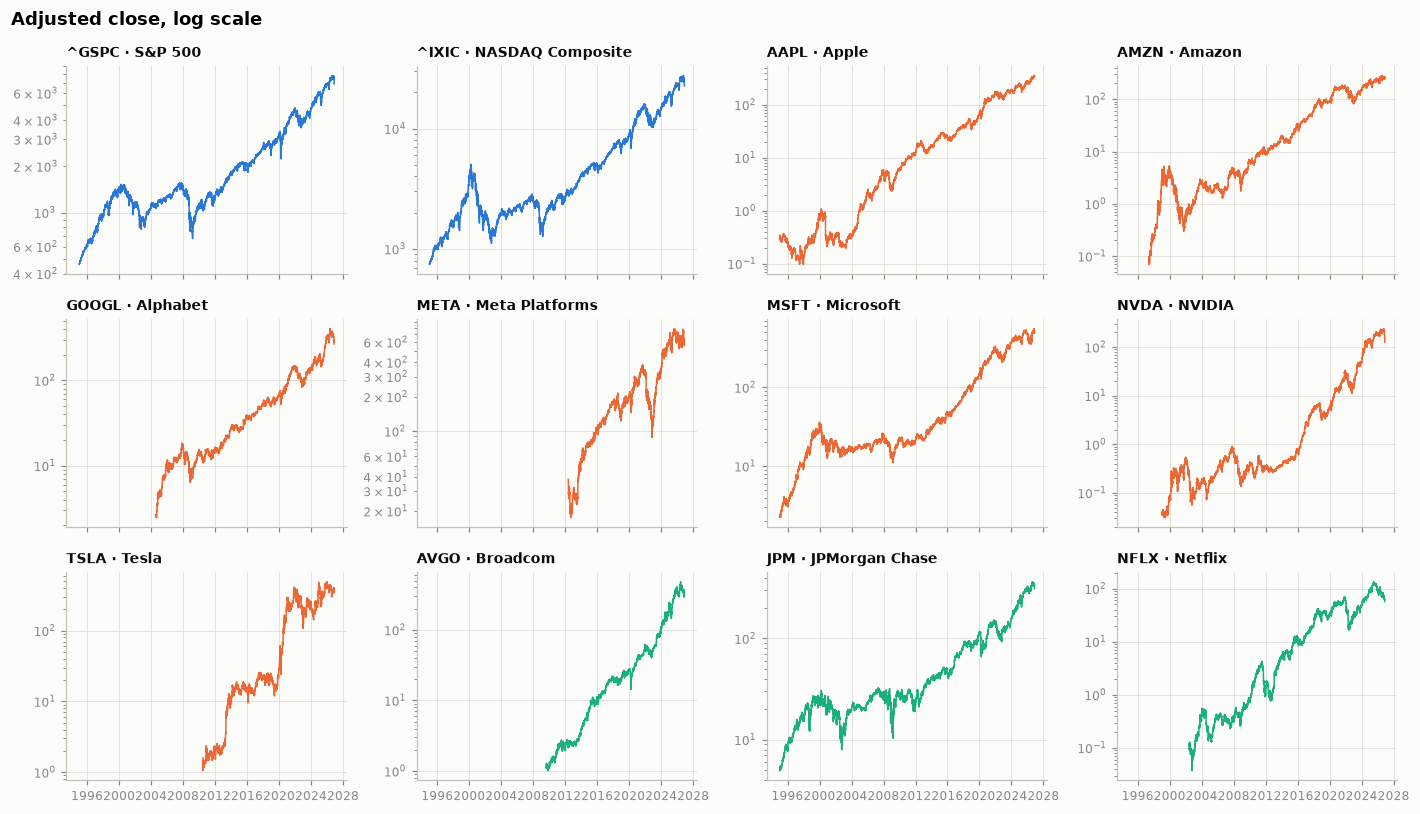

In [3]:
px = db.load_all_prices(engine, "adj_close")
order = inst.sort_values(["grp", "ticker"], key=lambda s: s.map({"index": 0, "mag7": 1, "extra": 2}).fillna(s))
fig, axes = plt.subplots(3, 4, figsize=(13, 7.5), sharex=True)
for ax, (_, row) in zip(axes.flat, order.iterrows()):
    s = px[row.ticker].dropna()
    ax.plot(s.index, s, color=viz.GROUP_COLORS[row.grp], lw=1)
    ax.set_yscale("log"); ax.set_title(f"{row.ticker} · {row['name']}", fontsize=9)
fig.suptitle("Adjusted close, log scale", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

## Growth since 2015, indexed to 100

Each panel holds at most four series (the Magnificent Seven are split in two), each
with a legend and a direct label at the line end.

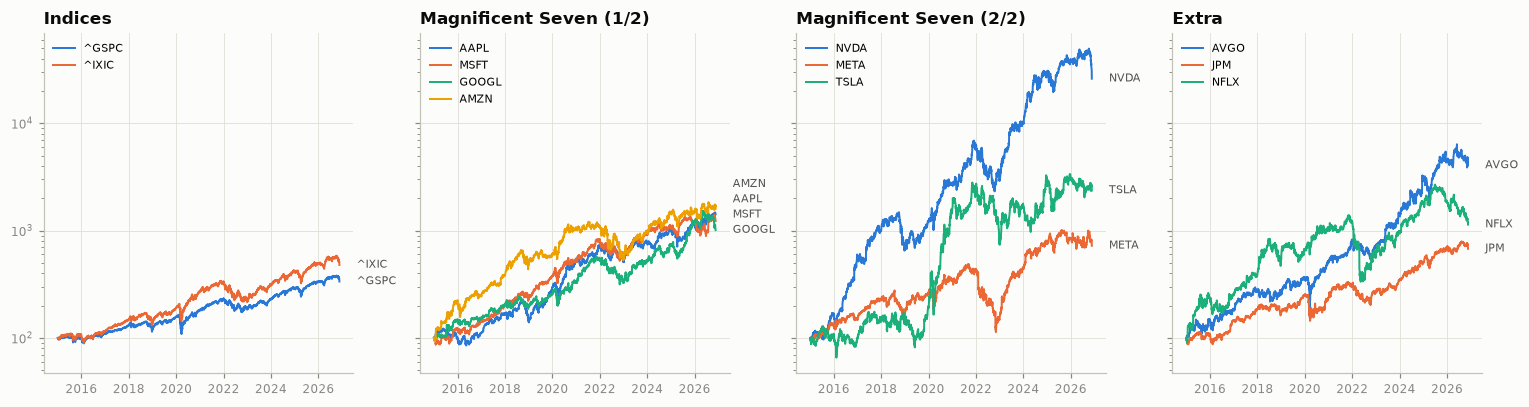

In [4]:
base = px.loc["2015-01-01":].ffill()
idx = 100 * base / base.bfill().iloc[0]
mag7 = inst.loc[inst.grp == "mag7", "ticker"].tolist()
panels = [("Indices", inst.loc[inst.grp == "index", "ticker"].tolist()),
          ("Magnificent Seven (1/2)", mag7[:4]), ("Magnificent Seven (2/2)", mag7[4:]),
          ("Extra", inst.loc[inst.grp == "extra", "ticker"].tolist())]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
for ax, (title, ticks) in zip(axes, panels):
    for i, t in enumerate(ticks):
        s = idx[t].dropna()
        ax.plot(s.index, s, lw=1.3, color=viz.SERIES[i], label=t)
    ax.set_yscale("log"); ax.set_title(title); ax.legend(loc="upper left", fontsize=7)
for ax, (title, ticks) in zip(axes, panels):
    viz.direct_labels(ax, {t: idx[t].dropna().iloc[-1] for t in ticks})
fig.tight_layout()

## Daily log-return statistics

In [5]:
r = np.log(px).diff()
stats = pd.DataFrame({
    "ann. return %": 252 * r.mean() * 100,
    "ann. vol %": np.sqrt(252) * r.std() * 100,
    "skew": r.skew(), "excess kurtosis": r.kurt(),
    "worst day %": r.min() * 100, "best day %": r.max() * 100,
    "max drawdown %": ((px / px.cummax()) - 1).min() * 100,
}).round(2).sort_values("ann. vol %")
stats

,ann. return %,ann. vol %,skew,excess kurtosis,worst day %,best day %,max drawdown %
ticker,,,,,,,
^GSPC,8.51,18.77,-0.38,10.41,-12.77,10.96,-56.78
^IXIC,10.72,24.24,-0.17,6.24,-13.15,13.25,-77.93
GOOGL,21.01,30.68,0.26,7.73,-13.51,18.23,-65.29
MSFT,16.83,30.96,-0.03,7.44,-16.96,17.87,-69.39
JPM,13.00,36.06,0.20,13.35,-23.23,22.39,-74.02
AVGO,32.40,38.48,-0.14,8.12,-22.21,21.86,-48.30
META,18.62,39.98,-0.37,20.14,-30.64,25.94,-76.74
AAPL,22.29,42.34,-2.40,76.75,-73.12,28.69,-81.80
AMZN,26.58,54.14,0.46,9.84,-28.46,29.62,-94.40


Fat tails (excess kurtosis far above 0) and large drawdowns are exactly the
regime LPPLS tries to anticipate: the model looks for *faster-than-exponential*
growth with accelerating log-periodic oscillations before such drawdowns.